##### Part 1-Text Processing and Exploratory Data Analysis

In [ ]:
# Keep file paths working when this notebook is opened from project_progress.
from pathlib import Path
import os
import zipfile
import shutil

_here = Path.cwd().resolve()
_project_root = next(
    (folder for folder in (_here, *_here.parents)
     if (folder / "project_progress").is_dir() and (folder / "data").is_dir()),
    None
)
if _project_root is None:
    raise FileNotFoundError("Open this notebook from inside the irwa-search-engine repository.")

_data_dir = _project_root / "data"
_needed = ("fashion_products.csv", "index_info.csv")
if any(not (_data_dir / name).exists() for name in _needed):
    _archive = _data_dir / "processed_data.zip"
    if _archive.is_file():
        with zipfile.ZipFile(_archive) as _zip:
            for _filename in _needed:
                if not (_data_dir / _filename).exists():
                    with _zip.open(_filename) as _source, (_data_dir / _filename).open("wb") as _dest:
                        shutil.copyfileobj(_source, _dest)
    else:
        raise FileNotFoundError("Missing data CSVs. Put processed_data.zip in data/ first.")

os.chdir(_project_root)
print("Project root:", Path.cwd())


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

import nltk
from nltk.stem import PorterStemmer
from nltk.tokenize import RegexpTokenizer
from nltk.corpus import stopwords

nltk.download("stopwords")


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

Before preprocessing, we should first load the fashion-product dataset and examine its attributes and data types.

In [ ]:

df = pd.read_csv("data/fashion_products.csv")

print("Dataset shape:", df.shape)

df.info()

display(df.head())


Dataset shape: (28080, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28080 entries, 0 to 28079
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pid              28080 non-null  object 
 1   title            28080 non-null  object 
 2   description      16927 non-null  object 
 3   brand            26071 non-null  object 
 4   category         28080 non-null  object 
 5   sub_category     28080 non-null  object 
 6   product_details  28080 non-null  object 
 7   seller           26437 non-null  object 
 8   out_of_stock     28080 non-null  bool   
 9   selling_price    28078 non-null  object 
 10  discount         27225 non-null  object 
 11  actual_price     27303 non-null  object 
 12  average_rating   25819 non-null  float64
 13  url              28080 non-null  object 
dtypes: bool(1), float64(1), object(12)
memory usage: 2.8+ MB


,pid,title,description,brand,category,sub_category,product_details,seller,out_of_stock,selling_price,discount,actual_price,average_rating,url
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,False,921,69% off,"2,999",3.9,https://www.flipkart.com/yorker-solid-men-mult...
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,False,499,66% off,"1,499",3.9,https://www.flipkart.com/yorker-solid-men-blue...
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,False,931,68% off,"2,999",3.9,https://www.flipkart.com/yorker-solid-men-mult...
3,TKPFCZ9ESZZ7YWEF,Solid Women Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005COMBO3'}, {'Closure': 'El...",Shyam Enterprises,False,911,69% off,"2,999",3.9,https://www.flipkart.com/yorker-solid-men-mult...
4,TKPFCZ9EVXKBSUD7,"Solid Women Brown, Grey Track Pants",Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005COMBO1'}, {'Closure': 'Dr...",Shyam Enterprises,False,943,68% off,"2,999",3.9,https://www.flipkart.com/yorker-solid-men-brow...


Before preprocessing we need to make sure that there are no missing values or duplicates in our dataset

In [ ]:

missing_values = df.isna().sum() # this function identifies missing values

empty_strings = df.apply(
    lambda col: col.map(
        lambda value: isinstance(value, str) and value.strip() == ""
    ).sum()
)# our strip function helps us identify any strings with spaces in them 


missing_report = pd.DataFrame({
    "Missing values": missing_values,
    "Empty strings": empty_strings
}) # our Dataframe oragnaizes our findinfs into a readable table 

display(missing_report)

# Check for duplicate records
print("Duplicate product IDs:", df["pid"].duplicated().sum())
print("Duplicate rows:", df.duplicated().sum())


,Missing values,Empty strings
pid,0,0
title,0,0
description,11153,0
brand,2009,0
category,0,0
sub_category,0,0
product_details,0,0
seller,1643,0
out_of_stock,0,0
selling_price,2,0


Duplicate product IDs: 0
Duplicate rows: 0


Before starting tokenization and stemming, our text-processinf functions shouldn't encounter any missing values. That is why we will create a separate copy of the dataset:

So we will replace missing textual values with empty strings and we will preserve numerical missing values.

In [6]:

# Create a working copy for preprocessing
processed_df = df.copy()

# Identify the textual fields used for indexing
text_fields = [
    "title", "description", "brand",
    "category", "sub_category",
    "seller", "product_details"
]
#any missing text will be replaced with an empty string : (so from NaN to "")
processed_df[text_fields] = processed_df[text_fields].fillna("")

# Will give 0 if our textual fields have no missing values
print(processed_df[text_fields].isna().sum())


title              0
description        0
brand              0
category           0
sub_category       0
seller             0
product_details    0
dtype: int64


### Text Preprocessing: 
Tokenization and Punction removal

In [ ]:

# This is the tokenizer we will use 
tokenizer = RegexpTokenizer(r"[a-z0-9]+")
#RegexpTokenizer() technically splits the text into the specified pattern between parenthesis. The pattern [a-z0-9]+ keeps the same sequence of words but in lowercawse, it keeps the numbers but excludes any punctuation

# Select an example product title
example_title = processed_df["title"].iloc[0]  #iloc[] allows us to select data based on its numberical position 

# Convert to lowercase and tokenize
tokens = tokenizer.tokenize(example_title.lower()) #.lower() converts uppercase letters to lowercase

print("Original title:", example_title)
print("Tokens:", tokens)


Original title: Solid Women Multicolor Track Pants
Tokens: ['solid', 'women', 'multicolor', 'track', 'pants']


###  Stop word removal
Next we should remove stop words

In [ ]:

# Load English stop words
stop_words = set(stopwords.words("english")) # this gives us common english stop words from NLTK

# Test using an example sentence
example_text = "A pair of pants for women"

# we Tokenize the example
example_tokens = tokenizer.tokenize(example_text.lower())

# Remove stop words
filtered_tokens = [
    word for word in example_tokens
    if word not in stop_words
]

print("Before:", example_tokens)
print("After:", filtered_tokens)


Before: ['a', 'pair', 'of', 'pants', 'for', 'women']
After: ['pair', 'pants', 'women']


Next up would be stemming which reduces words to common base form.

In [13]:

# Initialize the stemmer
stemmer = PorterStemmer()

# Apply stemming to our filtered tokens
stemmed_tokens = [
    stemmer.stem(word) for word in filtered_tokens
]

print("Before stemming:", filtered_tokens)
print("After stemming:", stemmed_tokens)


Before stemming: ['pair', 'pants', 'women']
After stemming: ['pair', 'pant', 'women']


In order to make our lives easier we will combine tokenization, stop-word removal, lowercasing and porter stemming into a single function.

We could argue that keeping the four preceeding steps is useless as we combined eveything into one function now, but these steps helped us understand and identify the effects of each function, therefore we will keep them as a mean of showing our thought process.

In [ ]:

def preprocess_text(text):
    """
    Preprocess text by applying lowercasing,
    tokenization, stop-word removal, and stemming.
    """

    # Handle missing or non-text values
    if not isinstance(text, str):
        return []
    text = text.lower()
    tokens = tokenizer.tokenize(text)
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [stemmer.stem(word) for word in tokens]

    return tokens


# Test our function
example = "A pair of pants for women"

print("Original:", example)
print("Processed:", preprocess_text(example))


Original: A pair of pants for women
Processed: ['pair', 'pant', 'women']


Now that we have out preprocess_text() function ready, we are going to use it for the preprocessing of the titles and descriptions of our documents 

In [17]:

processed_df["title_tokens"] = processed_df["title"].apply(preprocess_text)

processed_df["description_tokens"] = processed_df["description"].apply(preprocess_text)

display(processed_df[
    ["title", "title_tokens", "description_tokens"]
].head(3))


,title,title_tokens,description_tokens
0,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot..."
1,Solid Men Blue Track Pants,"[solid, men, blue, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot..."
2,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot..."


1.2-Preserving Product Information:
Our search engine needs to perform two things:
It needs to process tokens in order to find matching products from our dataset.
But it also needs the Original product information to actually display the results to the users 

In [19]:


required_fields = [
    "pid", "title", "description", "brand",
    "category", "sub_category", "product_details",
    "seller", "out_of_stock", "selling_price",
    "discount", "actual_price", "average_rating", "url"
]

# Verify that the original fields are preserved
missing_fields = [
    field for field in required_fields
    if field not in processed_df.columns
]

print("Missing required fields:", missing_fields)
print("Total products:", len(processed_df))
print("Unique product IDs:", processed_df["pid"].nunique())


Missing required fields: []
Total products: 28080
Unique product IDs: 28080


### 1.3 Handling the Other Textual Fields

We decided to preserve the textual fields separately instead of merging them into a single one.

This way, our inverted index will not only identify which products contain a term from the customer's search query, but also determine in which field that term appears.

This could also support future field-specific ranking improvements, meaning that we could give different importance to matches depending on the field in which they occur. For example, a product containing a query term in its title could receive a higher weight than a product containing the same term only in its description.

We apply the same preprocessing function to brand, category,
sub_category, and seller so we can stay consistent with the query preprocessing.

In [20]:

# Additional textual fields
additional_fields = [
    "brand", "category", "sub_category", "seller"
]

# Preprocess each field and store its tokens separately
for field in additional_fields:
    processed_df[f"{field}_tokens"] = processed_df[field].apply(preprocess_text)

# Examine the results
display(processed_df[
    ["brand", "brand_tokens",
     "category", "category_tokens",
     "seller", "seller_tokens"]
].head(3))


,brand,brand_tokens,category,category_tokens,seller,seller_tokens
0,York,[york],Clothing and Accessories,"[cloth, accessori]",Shyam Enterprises,"[shyam, enterpris]"
1,York,[york],Clothing and Accessories,"[cloth, accessori]",Shyam Enterprises,"[shyam, enterpris]"
2,York,[york],Clothing and Accessories,"[cloth, accessori]",Shyam Enterprises,"[shyam, enterpris]"


Let us process product_details field that contains structured information unlike the other textual fields.

The structured information looks as such:
[
    {"Style Code": "1005COMBO2"},
    {"Closure": "Elastic"},
    {"Fabric": "Cotton Blend"},
    {"Color": "Multicolor"}
]

That is why we should decide on a way to extract useful searchable terms without inexing other formatting( brakets, quotation marks, etc..)



First we will start by inspecting the structure 

In [21]:

# Examine the product details of the first product
details = processed_df["product_details"].iloc[0]

print("Data type:", type(details))
print("Product details:", details)


Data type: <class 'str'>
Product details: [{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'Color': 'Multicolor'}]


Now that we know that product_details contain structured information stored as a string in our CSV file, we will be:


Converting it back into a list of dictionaries, extracting the attribute names and values and finally applying our preprocessing function.



In [ ]:

from ast import literal_eval

def preprocess_product_details(details):

    # Convert the string into a Python list
    if isinstance(details, str):
        try:
            details = literal_eval(details)      # literal_eval() converts the string into a pything list of dictionaries 
        except (ValueError, SyntaxError):
            return []

    
    text_parts = []

    if isinstance(details, list):
        for item in details:
            if isinstance(item, dict):
                for key, value in item.items():   #.items() gives each attribute name and value
                    text_parts.append(f"{key} {value}")

    
    return preprocess_text(" ".join(text_parts))  # combines the extracted information into a single text string
# preprocess_text() is our preprocessing function 


# Apply to all products
processed_df["product_details_tokens"] = (
    processed_df["product_details"].apply(preprocess_product_details)
)

# Verify the result
print("Original details:")
print(processed_df["product_details"].iloc[0])

print("\nProcessed tokens:")
print(processed_df["product_details_tokens"].iloc[0])


Original details:
[{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'Color': 'Multicolor'}]

Processed tokens:
['style', 'code', '1005combo2', 'closur', 'elast', 'pocket', 'side', 'pocket', 'fabric', 'cotton', 'blend', 'pattern', 'solid', 'color', 'multicolor']


### 1.4 Handling Numerical and Boolean Fields

We believe that Numerical Attributes should be kept separate from the textual index
because they can be used for numerical comparisons and filtering.

Stock availability will be preserved as a Boolean attribute.

First we will inspect how these values are currently stored

In [23]:

numeric_fields = [
    "selling_price",
    "actual_price",
    "discount",
    "average_rating",
    "out_of_stock"
]

display(processed_df[numeric_fields].head())

print("\nData types:")
print(processed_df[numeric_fields].dtypes)


,selling_price,actual_price,discount,average_rating,out_of_stock
0,921,"2,999",69% off,3.9,False
1,499,"1,499",66% off,3.9,False
2,931,"2,999",68% off,3.9,False
3,911,"2,999",69% off,3.9,False
4,943,"2,999",68% off,3.9,False



Data types:
selling_price      object
actual_price       object
discount           object
average_rating    float64
out_of_stock         bool
dtype: object


#### Numerical Data Conversion

We convert prices, discounts, and ratings into numerical
values to support future filtering and analysis.
That is because users may want to filter products by price, discount, rating or availability, and in this case numerical comparison are more useful than text terms.(eg: A customer wants to find products that cost less than 200 euros)

The original values are preserved, while missing or invalid
values remain missing rather than being replaced with zero. 

In [ ]:

# Convert selling and actual prices
for field in ["selling_price", "actual_price"]:
    cleaned = (
        processed_df[field]
        .astype("string")
        .str.replace(",", "", regex=False)
        .str.replace(r"[^\d.]", "", regex=True)
    )

    processed_df[f"{field}_num"] = pd.to_numeric(
        cleaned, errors="coerce"
    )

# Extract the numerical discount percentage
processed_df["discount_pct"] = pd.to_numeric(
    processed_df["discount"]
    .astype("string")
    .str.extract(r"(\d+(?:\.\d+)?)")[0],
    errors="coerce"
)

# Ensure ratings are numeric
processed_df["average_rating_num"] = pd.to_numeric(
    processed_df["average_rating"],
    errors="coerce"      # if a value can't be converted Panda won't create an error and will replace it with NaN
)

# Preserve stock availability as Boolean
processed_df["out_of_stock_bool"] = processed_df["out_of_stock"]

# Display the converted values
display(processed_df[
    [
        "selling_price_num",
        "actual_price_num",
        "discount_pct",
        "average_rating_num",
        "out_of_stock_bool"
    ]
].head())


,selling_price_num,actual_price_num,discount_pct,average_rating_num,out_of_stock_bool
0,921,2999,69,3.9,False
1,499,1499,66,3.9,False
2,931,2999,68,3.9,False
3,911,2999,69,3.9,False
4,943,2999,68,3.9,False


### 1.5 Exporting the Preprocessed Data

After preprocessing the textual fields, we organize the resulting tokens into a separate dataset for indexing.

Each product keeps its unique product ID, and the seven textual fields are stored separately. The original product information is preserved in fashion_products.csv for displaying search results.

In [31]:

# Textual fields to be used in our inverted index
searchable_fields = [
    "title",
    "description",
    "brand",
    "category",
    "sub_category",
    "seller",
    "product_details"
]

# Create the indexing dataset
index_info = processed_df[["pid"]].copy()

for field in searchable_fields:
    index_info[field] = processed_df[f"{field}_tokens"]

# Export the dataset for Part 2
index_info.to_csv("data/index_info.csv", index=False)

print("Exported dataset shape:", index_info.shape)
print("Unique product IDs:", index_info["pid"].nunique())

display(index_info.head(3))


Exported dataset shape: (28080, 8)
Unique product IDs: 28080


,pid,title,description,brand,category,sub_category,seller,product_details
0,TKPFCZ9EA7H5FYZH,"[solid, women, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]","[style, code, 1005combo2, closur, elast, pocke..."
1,TKPFCZ9EJZV2UVRZ,"[solid, men, blue, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]","[style, code, 1005blue, closur, drawstr, elast..."
2,TKPFCZ9EHFCY5Z4Y,"[solid, men, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]","[style, code, 1005combo4, closur, elast, pocke..."


## 2. Exploratory Data Analysis (EDA)

In this section, we will be exploring the characteristics of our fashion
product dataset using statistical summaries and visualizations.

### 2.1 Text Length Analysis

After preprocessing, we shall examine the number of words in product titelss and description as it will help us understand the length of the documents that will later on be used for indexing and retrieval.



In [ ]:

# Create a separate dataframe for EDA
eda_df = processed_df.copy()  # the part 2 of this project depends on the preprocessing we executed in the Data preparation section, so to avoid changing part 2 that we already worked on as we won't be overwriting the input files 

# Count the number of tokens in titles and descriptions
eda_df["title_word_count"] = eda_df["title_tokens"].apply(len)
eda_df["description_word_count"] = eda_df["description_tokens"].apply(len)

# Display descriptive statistics
display(
    eda_df[
        ["title_word_count", "description_word_count"]
    ].describe().round(2)
)


,title_word_count,description_word_count
count,28080.00,28080.00
mean,6.27,18.84
std,1.98,26.72
min,1.00,0.00
25%,5.00,0.00
50%,6.00,9.00
75%,7.00,29.00
max,31.00,579.00


In [ ]:
#that is something we also saw in the data preparation phase
missing_descriptions = df["description"].isna().sum()
missing_percentage = missing_descriptions / len(df) * 100

print("Missing descriptions:", missing_descriptions)
print(f"Percentage: {missing_percentage:.2f}%")

print("Descriptions with zero processed tokens:",
      (eda_df["description_word_count"] == 0).sum())


Missing descriptions: 11153
Percentage: 39.72%
Descriptions with zero processed tokens: 11153


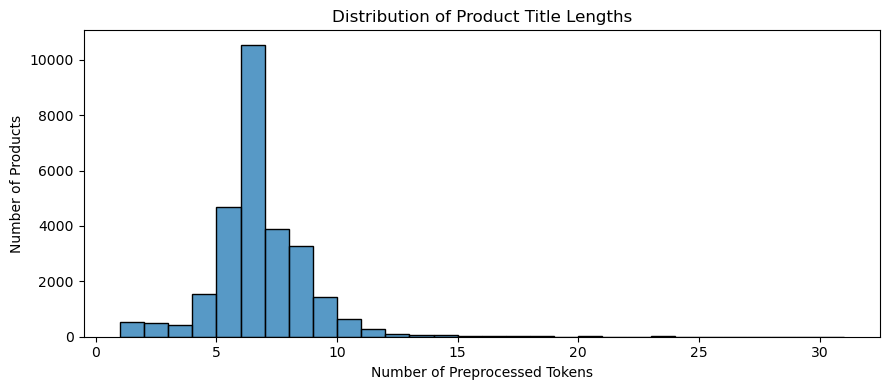

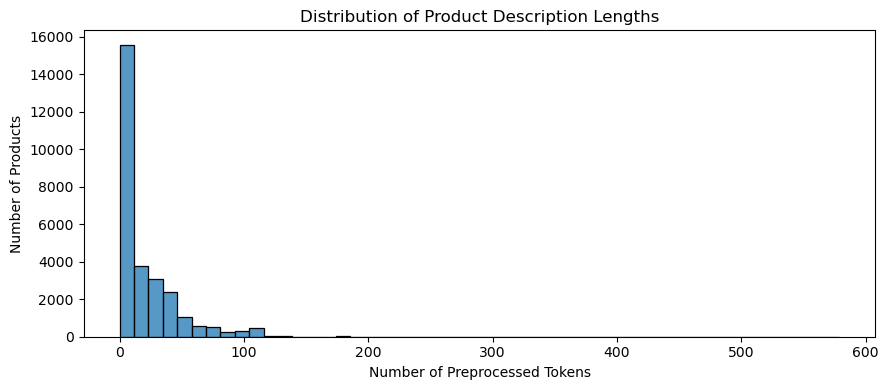

In [33]:

# Distribution of title lengths
plt.figure(figsize=(9, 4))

sns.histplot(
    eda_df["title_word_count"],
    bins=30
)

plt.title("Distribution of Product Title Lengths")
plt.xlabel("Number of Preprocessed Tokens")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


# Distribution of description lengths
plt.figure(figsize=(9, 4))

sns.histplot(
    eda_df["description_word_count"],
    bins=50
)

plt.title("Distribution of Product Description Lengths")
plt.xlabel("Number of Preprocessed Tokens")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


### 2.2 Vocabulary Size and Word Frequency Analysis
Vocabulary size and word frequencies are important as thet help us understand which terms are common across the product collection.

Therefore we should determine: 

The number unique terms are in our dataset

The most frequent words  in titles and descriptions

And finally the information we get about our search engine based on these frequencies.


In [ ]:

from collections import Counter

# Count term occurrences in titles and descriptions
title_frequency = Counter(
    term
    for tokens in eda_df["title_tokens"]
    for term in tokens
)

description_frequency = Counter(
    term
    for tokens in eda_df["description_tokens"]
    for term in tokens
)

# Calculates our vocabulary size across the collection
vocabulary = set()  # this function stores only unique terms

for field in searchable_fields:
    for tokens in eda_df[f"{field}_tokens"]:
        vocabulary.update(tokens)

print("Total vocabulary size:", len(vocabulary))
print("Unique terms in titles:", len(title_frequency))
print("Unique terms in descriptions:", len(description_frequency))

# Find the 15 most frequent terms in each field
top_title_terms = pd.DataFrame(
    title_frequency.most_common(15),
    columns=["Term", "Frequency"]
)

top_description_terms = pd.DataFrame(
    description_frequency.most_common(15),
    columns=["Term", "Frequency"]
)

print("\nMost frequent terms in titles:")
display(top_title_terms)

print("\nMost frequent terms in descriptions:")
display(top_description_terms)


Total vocabulary size: 21073
Unique terms in titles: 738
Unique terms in descriptions: 4697

Most frequent terms in titles:


,Term,Frequency
0,shirt,15838
1,women,13146
2,men,13060
3,neck,11952
4,solid,9246
5,round,8301
6,print,8123
7,pack,4839
8,blue,4378
9,fit,3923



Most frequent terms in descriptions:


,Term,Frequency
0,shirt,18321
1,cotton,10139
2,wear,9353
3,comfort,8836
4,look,6413
5,casual,6034
6,fit,5831
7,made,5643
8,fabric,5516
9,print,4888


Most frequent terms in descriptions:


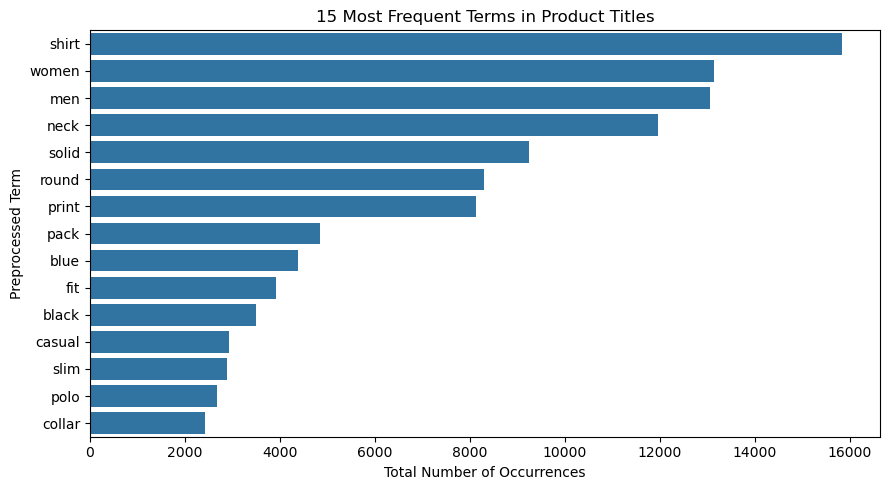

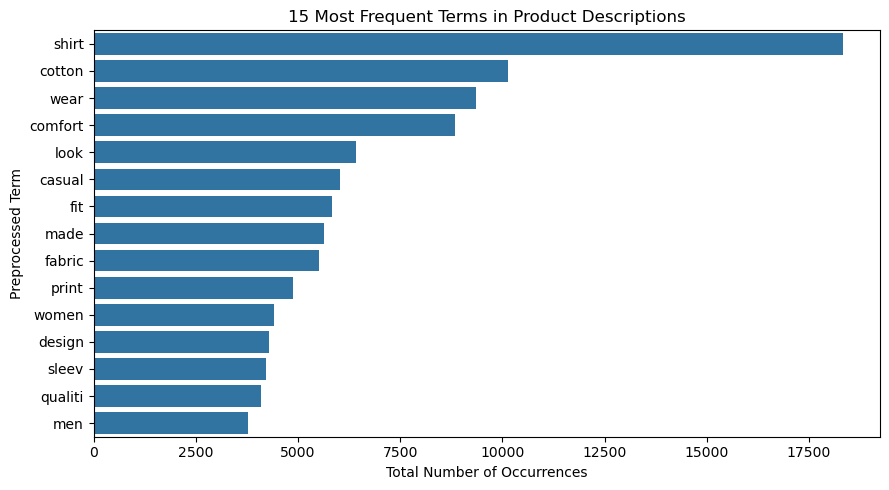

In [37]:

# will  Display the most frequent description terms
print("Most frequent terms in descriptions:")
#display(top_description_terms)

# Visualization the 15 most frequent terms in each field
for field_name, frequency in [
    ("Titles", title_frequency),
    ("Descriptions", description_frequency)
]:
    top_terms = pd.DataFrame(
        frequency.most_common(15),
        columns=["Term", "Frequency"]
    )

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=top_terms,
        x="Frequency",
        y="Term"
    )

    plt.title(f"15 Most Frequent Terms in Product {field_name}")
    plt.xlabel("Total Number of Occurrences")
    plt.ylabel("Preprocessed Term")
    plt.tight_layout()
    plt.show()


### 2.3 Average Sentence Length

For our average sentence length analysis we will be using original descriptions. This will tell us how detailed the products descriptions are.

count    16927.00
mean        15.42
std          8.94
min          1.00
25%         10.00
50%         14.43
75%         18.67
max        156.00
Name: avg_sentence_length, dtype: float64

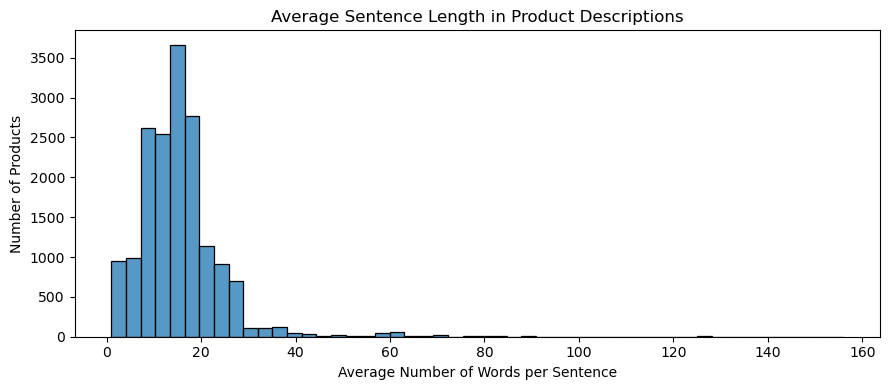

In [ ]:

import re

def average_sentence_length(text):
    if not isinstance(text, str) or not text.strip():
        return np.nan

    # we split description into sentences 
    sentences = re.split(r"[.!?]+", text)

    # count words except in empty ones 
    lengths = [
        len(re.findall(r"[a-zA-Z0-9]+", sentence))
        for sentence in sentences
        if sentence.strip()
    ]

    return np.mean(lengths) if lengths else np.nan


# Calculate average sentence length per product
eda_df["avg_sentence_length"] = (
    eda_df["description"].apply(average_sentence_length)
)

# Display statistics
display(eda_df["avg_sentence_length"].describe().round(2))

# Plot the distribution
plt.figure(figsize=(9, 4))

sns.histplot(
    eda_df["avg_sentence_length"].dropna(),
    bins=50
)

plt.title("Average Sentence Length in Product Descriptions")
plt.xlabel("Average Number of Words per Sentence")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


2.4 Price Distribution

We are done with textual attributes, so we are moving to numerical ones. We will start by analyzing the selling price and the actual price for us to understand the price ranges in our dataset.

This will also emphasize the importance of numerical attributes when it comes lately to product filtering and sorting. ( eg: retrieving a product with a selling price below a certain threshold)

,selling_price_num,actual_price_num
count,28078.0,27303.0
mean,705.64,1455.53
std,549.68,939.98
min,99.0,150.0
25%,390.0,849.0
50%,545.0,1199.0
75%,820.0,1799.0
max,7999.0,12999.0


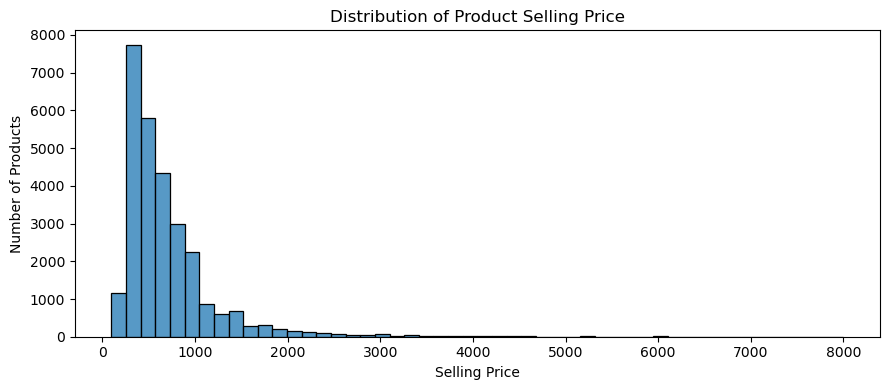

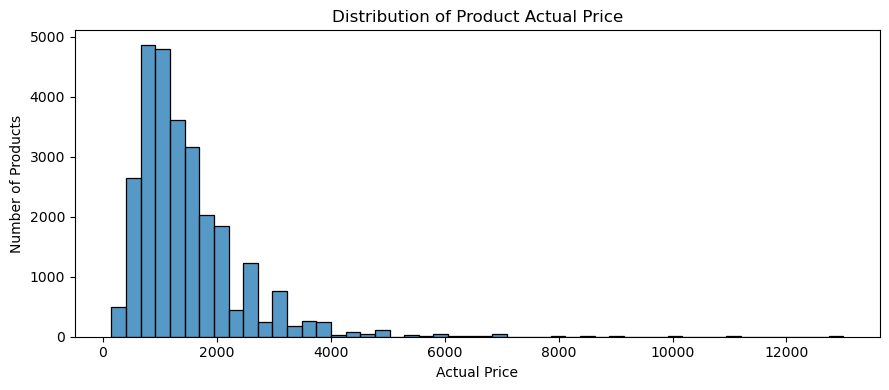

In [39]:

# Descriptive statistics for product prices
price_columns = ["selling_price_num", "actual_price_num"]

display(eda_df[price_columns].describe().round(2))

# Plot the price distributions
for column, label in [
    ("selling_price_num", "Selling Price"),
    ("actual_price_num", "Actual Price")
]:
    prices = eda_df[column].dropna()

    plt.figure(figsize=(9, 4))

    sns.histplot(prices, bins=50)

    plt.title(f"Distribution of Product {label}")
    plt.xlabel(label)
    plt.ylabel("Number of Products")
    plt.tight_layout()
    plt.show()


### 2.5 Rating and Discount Distributions

Next we will examine if product ratings are concentrated around certain values, how large the discounts typically are and how these attributes could support filtering or sorting.

,average_rating_num,discount_pct
count,25819.00,27225.0
mean,3.63,50.26
std,0.66,16.89
min,1.00,1.0
25%,3.20,40.0
50%,3.80,53.0
75%,4.10,63.0
max,5.00,87.0


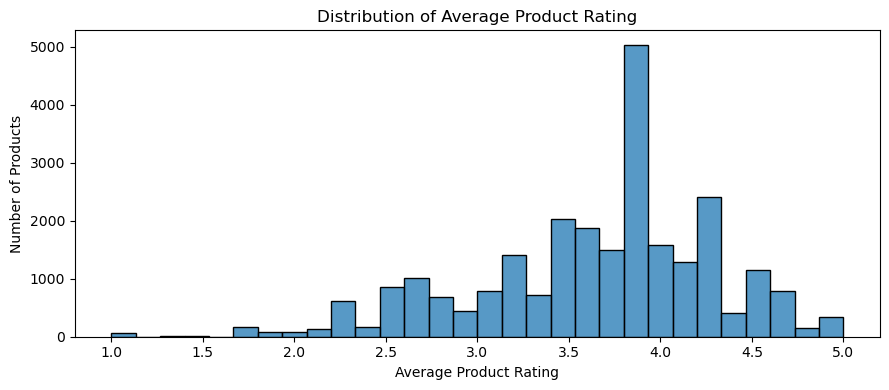

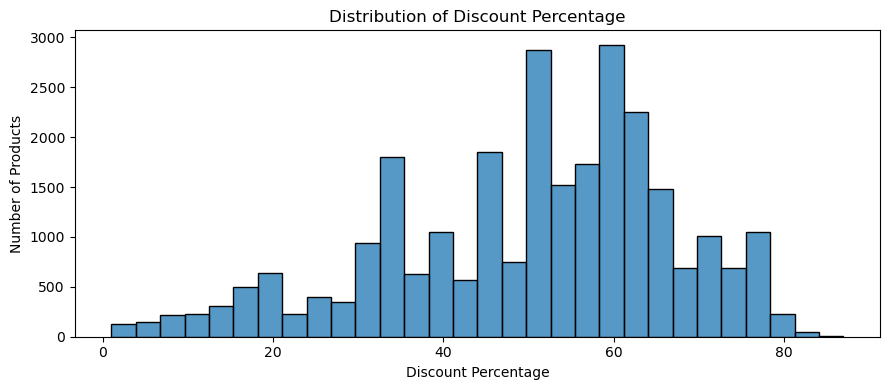

In [40]:


rating_discount_columns = [
    "average_rating_num",
    "discount_pct"
]

display(
    eda_df[rating_discount_columns].describe().round(2)
)


for column, label in [
    ("average_rating_num", "Average Product Rating"),
    ("discount_pct", "Discount Percentage")
]:
    values = eda_df[column].dropna()

    plt.figure(figsize=(9, 4))

    sns.histplot(
        values,
        bins=30
    )

    plt.title(f"Distribution of {label}")
    plt.xlabel(label)
    plt.ylabel("Number of Products")
    plt.tight_layout()
    plt.show()


### 2.6 Most Frequent Brands and Sellers

Now, let's identify whcih brandsd and sellers have the largest number of products in the dataset.

Missing values are excluded from the rankings to ensure that
we only count identified brands and sellers.


Top 10 brands:


brand
ECKO Unl        951
Free Authori    860
ARBO            806
REEB            802
Pu              798
True Bl         793
Keo             660
Amp             585
Black Beat      548
vims rai        503
Name: count, dtype: Int64

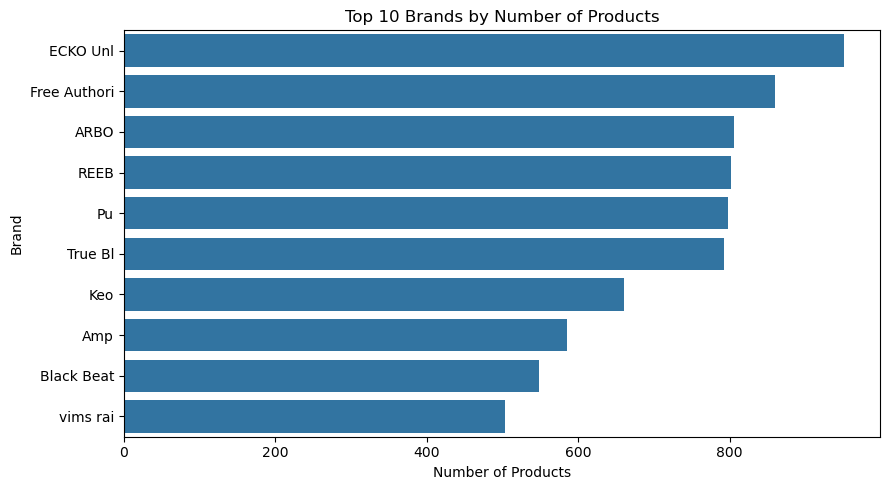


Top 10 sellers:


seller
RetailNet                1411
SandSMarketing            887
BioworldMerchandising     842
ARBOR                     783
Keoti                     660
AFFGARMENTS               587
Black Beatle              548
AMALGUS ENTERPRISE        477
Tayab Manch Fashions      436
KAPSONSRETAILPVTLTD       415
Name: count, dtype: Int64

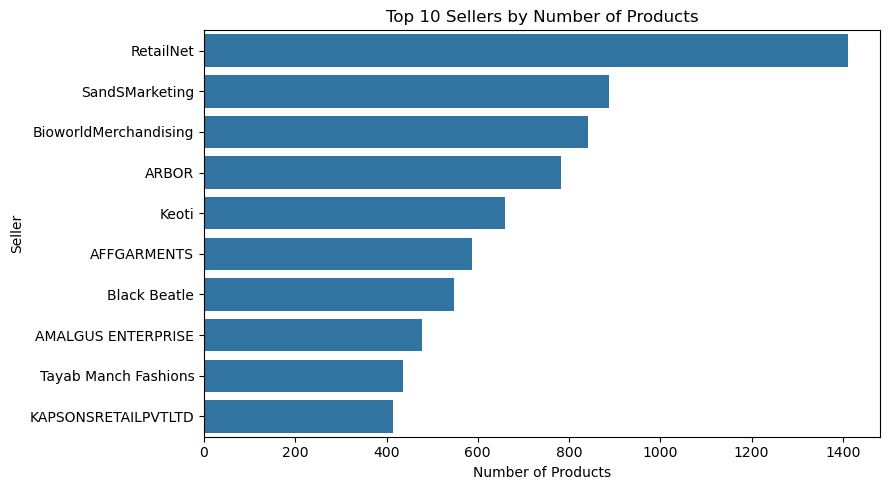

In [ ]:

#We will analyze the 10 most frequent brands and sellers
for field in ["brand", "seller"]:

    # we Exclude missing and empty values
    values = eda_df[field].astype("string").str.strip()
    values = values.replace("", pd.NA).dropna()


    top_10 = values.value_counts().head(10)

    print(f"\nTop 10 {field}s:")
    display(top_10)

    # Create horizontal bar chart
    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=top_10.values,
        y=top_10.index
    )

    plt.title(f"Top 10 {field.capitalize()}s by Number of Products")
    plt.xlabel("Number of Products")
    plt.ylabel(field.capitalize())
    plt.tight_layout()
    plt.show()


### 2.7 Stock Availability

Now we will examine the products markes as in stock or out of stock. 

This would later help us for filtering options, as customer will get to see available products, or will at least know if a product is out of stock.

,Status,Number of Products,Percentage (%)
0,In Stock,26436,94.15
1,Out of Stock,1644,5.85


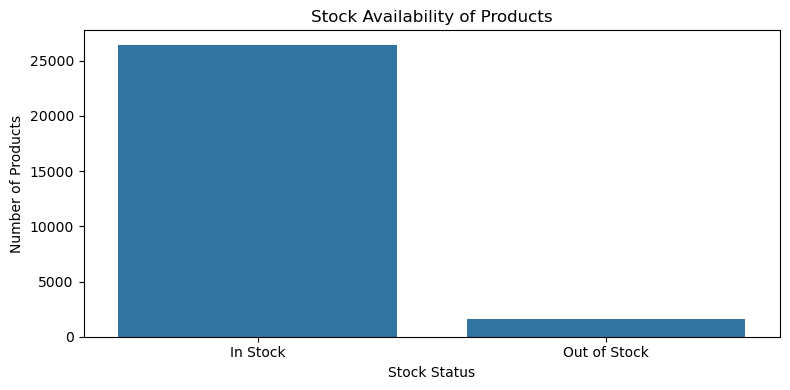

In [ ]:

# we will Count products by stock availability
stock_counts = (
    eda_df["out_of_stock_bool"]
    .value_counts()
    .reindex([False, True], fill_value=0)
)

stock_labels = ["In Stock", "Out of Stock"]

# Calculate percentages
stock_percentages = stock_counts / len(eda_df) * 100


stock_summary = pd.DataFrame({
    "Status": stock_labels,
    "Number of Products": stock_counts.values,
    "Percentage (%)": stock_percentages.values.round(2)
})

display(stock_summary)


plt.figure(figsize=(8, 4))

sns.barplot(
    x=stock_labels,
    y=stock_counts.values
)

plt.title("Stock Availability of Products")
plt.xlabel("Stock Status")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


### 2.8 Category and Subcategory Distribution
Now we will examine how products are distributed across categories and subcategories..

This will us understand the composition of our dataset and will allow us to know if certain product categories are more common than others.

Products by category:


category
Clothing and Accessories    27118
Footwear                      920
Bags, Wallets & Belts          41
Toys                            1
Name: count, dtype: int64

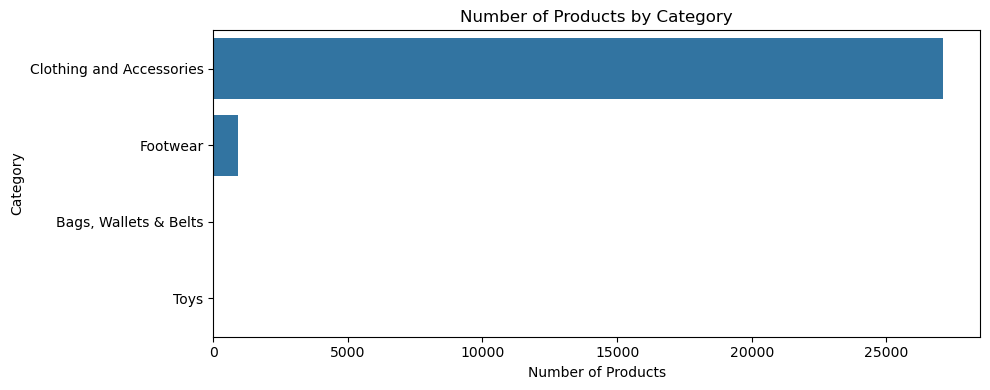


Top 10 subcategories:


sub_category
Topwear                            15310
Bottomwear                          3666
Winter Wear                         2493
Innerwear and Swimwear              1762
Clothing Accessories                1742
Kurtas, Ethnic Sets and Bottoms     1180
Men's Footwear                       920
Fabrics                              534
Sleepwear                            122
Blazers, Waistcoats and Suits        103
Name: count, dtype: int64

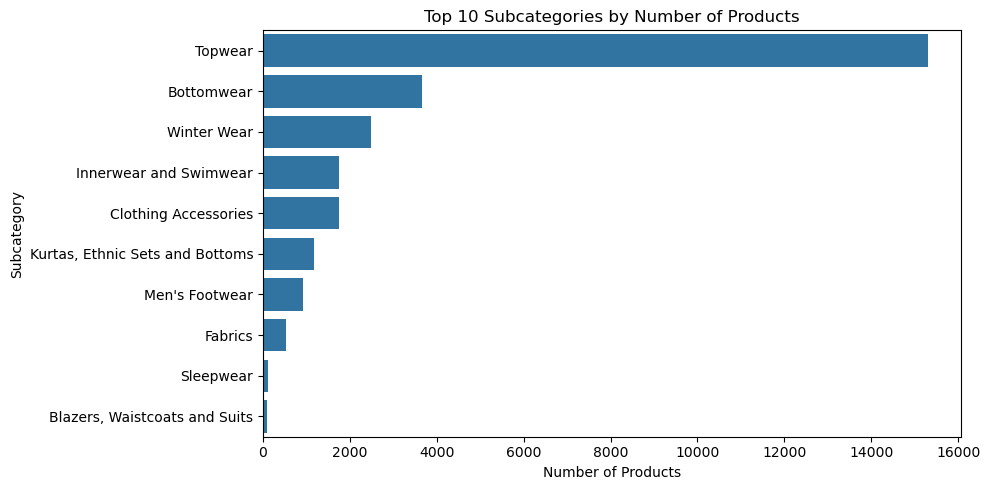

In [43]:


category_counts = eda_df["category"].value_counts()

print("Products by category:")
display(category_counts)


plt.figure(figsize=(10, 4))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Number of Products by Category")
plt.xlabel("Number of Products")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


# this is to find the 10 most common subcategories
subcategory_counts = (
    eda_df["sub_category"].value_counts().head(10)
)

print("\nTop 10 subcategories:")
display(subcategory_counts)

# Plot subcategory distribution
plt.figure(figsize=(10, 5))

sns.barplot(
    x=subcategory_counts.values,
    y=subcategory_counts.index
)

plt.title("Top 10 Subcategories by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Subcategory")
plt.tight_layout()
plt.show()


### 2.9 Word Cloud Visualization

A word cloud will display most frequently occurring terms in the dataset.

The size of each word will reflect this freqency.



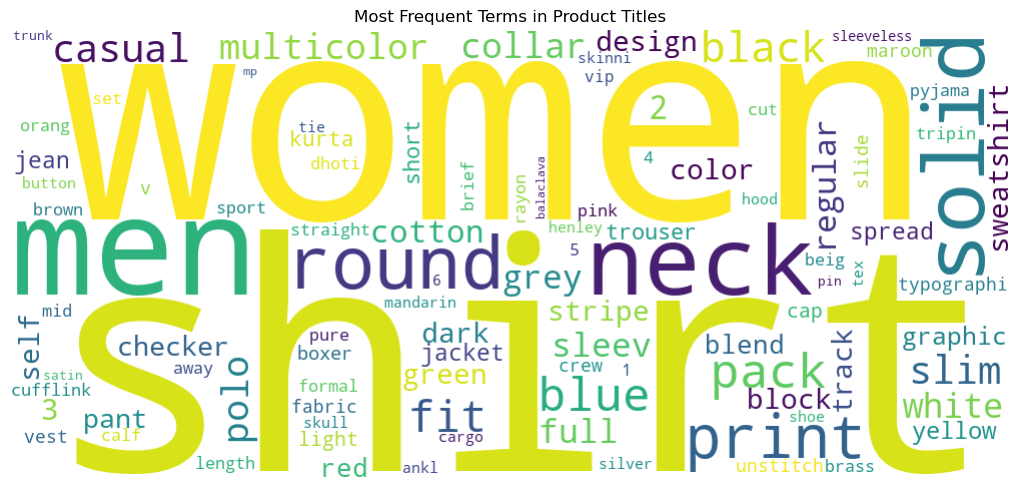

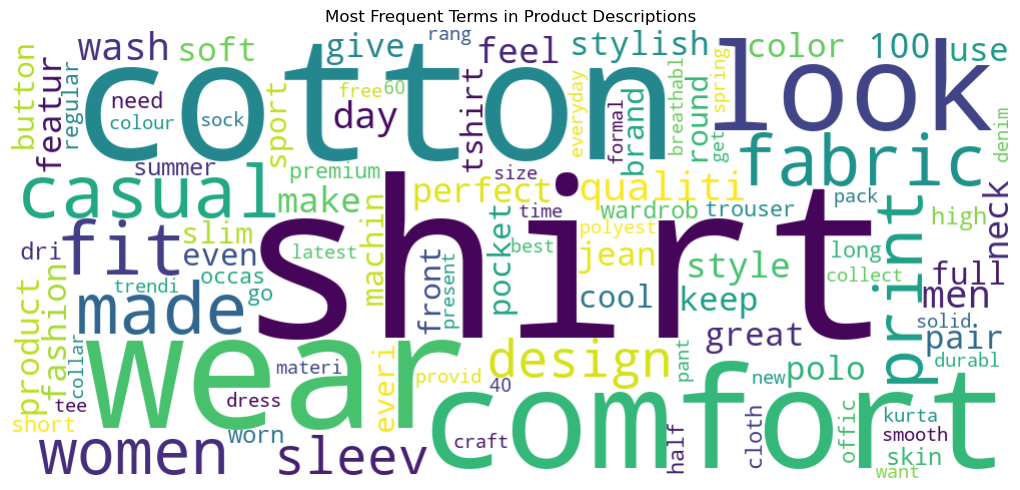

In [44]:

from wordcloud import WordCloud

for field_name, frequencies in [
    ("Titles", title_frequency),
    ("Descriptions", description_frequency)
]:
    wordcloud = WordCloud(
        width=1000,
        height=450,
        background_color="white",
        max_words=100,
        collocations=False
    ).generate_from_frequencies(frequencies)

    plt.figure(figsize=(11, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Most Frequent Terms in Product {field_name}")
    plt.tight_layout()
    plt.show()


### 2.10 Product Rankings
Here it is just to show the highest-rated products 

In [45]:

# Show the five highest-rated products
print("Top 5 highest-rated products:")
display(
    eda_df[["title", "average_rating_num"]]
    .dropna()
    .sort_values("average_rating_num", ascending=False)
    .head(5)
)

# Show the five most expensive products
print("Top 5 most expensive products:")
display(
    eda_df[["title", "selling_price_num"]]
    .dropna()
    .sort_values("selling_price_num", ascending=False)
    .head(5)
)

# Show the five most discounted products
print("Top 5 most discounted products:")
display(
    eda_df[["title", "discount_pct"]]
    .dropna()
    .sort_values("discount_pct", ascending=False)
    .head(5)
)


Top 5 highest-rated products:


,title,average_rating_num
22361,Men Brief (Pack of 5),5.0
8403,VIP Women Vest (Pack of 8),5.0
14764,Graphic Print Women Round Neck White T-Shirt,5.0
13240,Men Brief (Pack of 5),5.0
10472,Men Slim Fit Printed Spread Collar Casual Shirt,5.0


Top 5 most expensive products:


,title,selling_price_num
2067,Solid Women Track Suit,7999
11010,Checkered Single Breasted Party Women Full Sle...,7998
26089,Full Sleeve Printed Men Sweatshirt,7799
25815,Full Sleeve Solid Women Casual Jacket,7799
6895,Skinny Men Blue Jeans,7794


Top 5 most discounted products:


,title,discount_pct
906,Printed Women Round Neck White T-Shirt,87
903,Printed Women Round Neck White T-Shirt,86
902,Printed Women Round Neck Grey T-Shirt,86
18249,Printed Men Round Neck Multicolor T-Shirt (Pa...,85
9811,Solid Balclava Cap,84
